# Demand Forecasting
### How many units of each product will customers order in the next four weeks?

**Dataset:** UCI Online Retail II, the same 1.07 million invoice lines as notebook 01, now viewed product by product and week by week.
**Stack:** dbt on DuckDB, pandas, scikit-learn (gradient boosting with Poisson and quantile losses), conformal prediction.

Notebook 01 asked *which customers* will come back. This notebook asks the operational twin of that question: *how much of each product* will be ordered, so purchasing can buy the right stock before the Christmas peak.

| # | Step | Question it answers |
|---|------|---------------------|
| 1 | Business problem | What decision does the forecast support, and how is it judged? |
| 2 | Data and dbt models | How is weekly demand built from invoice lines? |
| 3 | Demand data audit | What in the data would mislead a forecast? |
| 4 | Exploratory analysis | How seasonal, concentrated and intermittent is demand? |
| 5 | Price architecture | How does this business set prices? |
| 6 | Can this data measure price elasticity? | A natural experiment, and why its answer is not enough |
| 7 | Validation design | How do we test a forecast honestly? |
| 8 | Baselines | What would a planner do without a model? |
| 9 | Global gradient boosting model | One model for a thousand products |
| 10 | Results | Accuracy by method, horizon, category and demand type |
| 11 | Prediction intervals | How much stock covers 80% of outcomes? |
| 12 | What drives the forecast | Feature importance |
| 13 | The December 2011 forecast | The output purchasing receives |
| 14 | Conclusions | What we learned |
| 15 | Limitations and next steps | What we would do next |

Production code lives in `src/retail_intelligence/demand.py`; this notebook calls the same functions, so the numbers here match the app and `reports/demand_metrics.json`.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")   # keep the notebook output focused on results

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from retail_intelligence import demand as dm
from retail_intelligence.config import DATA_PROCESSED, DBT_DIR, ROOT
from retail_intelligence.plotting import BLUE, CATEGORICAL, GRAY, INK, LIGHT_BLUE, MUTED, RED, apply_style, save

apply_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
con = duckdb.connect(str(DATA_PROCESSED / "warehouse.duckdb"), read_only=True)
con.execute(f"SET file_search_path = '{DBT_DIR}'")   # dbt views read the Parquet source relative to dbt/

## 1. Business problem

The wholesaler buys most of its range from overseas suppliers, so stock has to be ordered weeks ahead. Every four weeks purchasing decides how many units of each product to buy. Two mistakes are expensive:

- **Under-forecasting** means empty shelves in the warehouse during the autumn peak, when gift shops order for Christmas. Those orders go to a competitor.
- **Over-forecasting** ties up cash in stock that may only sell next year, and seasonal items may never sell.

**The forecast:** for every product, the total units customers will order in the next **four weeks**, with an 80% range (10th to 90th percentile) to size safety stock.

**How it is judged**, always against simple methods a planner could use in a spreadsheet:

| Metric | Definition | Why |
|---|---|---|
| WAPE | Total absolute error divided by total demand | Error in units, weighted towards the products that matter most; well defined when many weeks are zero |
| Bias | Total forecast minus total demand, divided by total demand | A forecast can have a good WAPE and still be systematically low, which empties shelves |
| Catalogue WAPE | WAPE of the total units across all products | Warehouse space, staffing and cash depend on the total |
| Interval coverage | Share of actual outcomes inside the 80% range | A range is only useful if it is honest |

## 2. Data and dbt models

Demand is not the same as customers. Notebook 01 dropped guest orders (no customer ID) because they cannot be linked to a person; for demand they are real units leaving the warehouse, so they are kept. The dbt staging layer was therefore split in two:

```
stg_sales_lines      all channels, cleaning rules 1, 3, 4, 5, channel = Registered or Guest
 ├── stg_transactions      registered customers only (rule 2), feeds notebook 01 unchanged
 ├── int_product_weeks     units, revenue, orders and list price per product and week
 │    └── product_weekly_demand   complete product x week grid, zeros included
 └── dim_products          main description and a merchandise category per product
```

The dataset has no product category, so `dim_products` assigns one with keyword rules kept in a dbt seed (`seeds/product_category_rules.csv`), matched as whole words against the description. Rules in a seed are reviewable in a pull request and testable, unlike a dictionary buried in a notebook.

In [2]:
demand = dm.load_demand()
products = dm.load_products()
Y, product_ids, weeks = dm.to_matrix(demand)
display(Markdown(
    f"**Forecasting universe:** {len(product_ids):,} products x {len(weeks)} weeks "
    f"({weeks[0]:%d %b %Y} to {weeks[-1]:%d %b %Y}), {len(demand):,} product-weeks."))
demand.head()

**Forecasting universe:** 1,041 products x 104 weeks (07 Dec 2009 to 28 Nov 2011), 108,264 product-weeks.

,product_id,week_start,units,revenue,orders,customers,guest_units,avg_unit_price,list_price
0,10133,2009-12-07,48.000,40.800,5,5,0.000,0.850,0.850
1,10133,2009-12-14,21.000,17.850,3,3,0.000,0.850,0.850
2,10133,2009-12-21,0.000,0.000,0,0,0.000,NaN,NaN
3,10133,2009-12-28,0.000,0.000,0,0,0.000,NaN,NaN
4,10133,2010-01-04,150.000,108.000,1,1,0.000,0.720,0.720


In [3]:
coverage = con.sql("""
    with lines as (
        select l.*, u.product_id is not null as in_universe
        from stg_sales_lines l
        left join (select distinct product_id from read_parquet('../data/processed/product_weekly_demand.parquet')) u
          using (product_id)
        where not is_cancellation and quantity > 0
    )
    select count(distinct product_id) as products,
           count(distinct product_id) filter (where in_universe) as products_in_universe,
           sum(quantity) filter (where in_universe) / sum(quantity) as share_of_units,
           sum(revenue) filter (where in_universe) / sum(revenue) as share_of_revenue
    from lines
""").df()
coverage.style.format({"products": "{:,}", "products_in_universe": "{:,}", "share_of_units": "{:.1%}", "share_of_revenue": "{:.1%}"}).hide(axis="index")

products,products_in_universe,share_of_units,share_of_revenue
"4,903","1,041",62.7%,63.2%


**Universe rule.** A product enters the forecast if it sold in at least 70 of the 104 weeks (`min_active_weeks` in `dbt_project.yml`). That keeps about a fifth of the catalogue but most of the volume and revenue. Products outside it are new, short-lived or rare; they need a different method (see section 15).

## 3. Demand data audit

Notebook 01 audited the invoice lines. This audit looks at what would specifically distort a weekly forecast.

In [4]:
first_last = con.sql("""
    select min(invoiced_at)::date as first_day, max(invoiced_at)::date as last_day,
           dayname(min(invoiced_at)) as first_weekday, dayname(max(invoiced_at)) as last_weekday
    from stg_sales_lines
""").df()
weekly_total = demand.groupby("week_start").units.sum()
closed = weekly_total[weekly_total == 0]
channel = con.sql("""
    select channel, sum(quantity) as units, sum(revenue) as revenue
    from stg_sales_lines where not is_cancellation and quantity > 0 group by 1
""").df().set_index("channel")
channel = channel / channel.sum()
cancel = con.sql("""
    select -sum(quantity) filter (where is_cancellation) / sum(quantity) filter (where not is_cancellation) as cancelled_share
    from stg_sales_lines
    where product_id in (select distinct product_id from read_parquet('../data/processed/product_weekly_demand.parquet'))
""").fetchall()[0][0]
audit = pd.DataFrame([
    ("Partial weeks at the edges", f"Data starts on a {first_last.first_weekday[0]} and ends on a {first_last.last_weekday[0]}",
     "Only complete Monday-to-Sunday weeks are kept"),
    ("Weeks with no trading", ", ".join(f"{d:%d %b %Y}" for d in closed.index),
     "Kept as explicit zero weeks so 52-week lags stay aligned"),
    ("Guest orders", f"{channel.loc['Guest', 'units']:.1%} of units, {channel.loc['Guest', 'revenue']:.1%} of revenue",
     "Included: they are real demand"),
    ("Cancellations in the universe", f"{cancel:.1%} of units sold are later cancelled",
     "Demand is measured as gross orders; small, noted as a limitation"),
    ("Products without sales in a week", f"{(Y == 0).mean():.1%} of product-weeks are zero",
     "Kept: the model must learn intermittent demand"),
], columns=["check", "finding", "decision"])
audit.style.hide(axis="index")

check,finding,decision
Partial weeks at the edges,Data starts on a Tuesday and ends on a Friday,Only complete Monday-to-Sunday weeks are kept
Weeks with no trading,"28 Dec 2009, 27 Dec 2010",Kept as explicit zero weeks so 52-week lags stay aligned
Guest orders,"6.2% of units, 13.1% of revenue",Included: they are real demand
Cancellations in the universe,2.1% of units sold are later cancelled,"Demand is measured as gross orders; small, noted as a limitation"
Products without sales in a week,15.2% of product-weeks are zero,Kept: the model must learn intermittent demand


The Christmas closure matters more than it looks. If the empty week were simply missing, "the same week last year" would point one week off for every date after it, and the strongest seasonal signal in the data would be blurred. The dbt model generates every calendar week explicitly, and a dbt test (`assert_demand_grid_complete`) fails the build if any product is missing a week.

## 4. Exploratory analysis

### 4.1 Seasonality: the autumn peak dominates the year

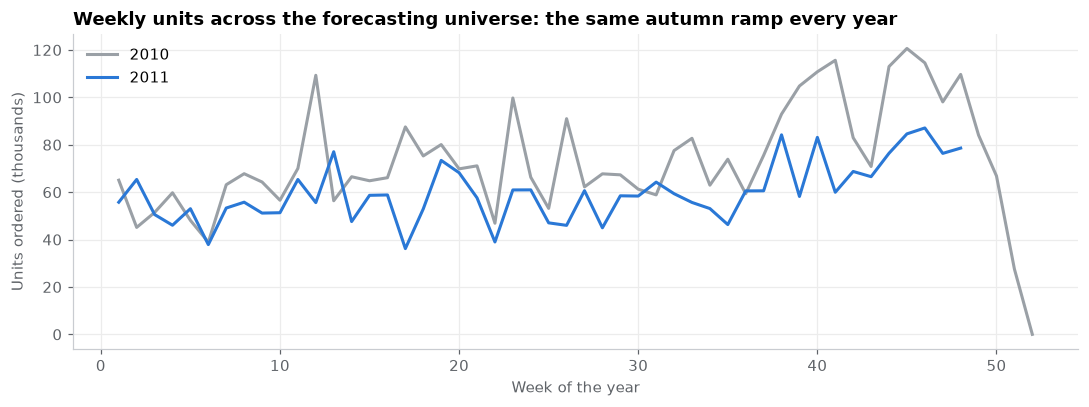

September to November 2011 averaged **1.3 times** the weekly units of January to July.

In [5]:
tot = weekly_total.to_frame("units")
tot["year"] = tot.index.year
tot["week"] = tot.index.isocalendar().week.values
fig, ax = plt.subplots(figsize=(10, 3.8))
for year, color in [(2010, GRAY), (2011, BLUE)]:
    s = tot[tot.year == year]
    ax.plot(s.week, s.units / 1e3, color=color, lw=2, label=str(year))
ax.set_xlabel("Week of the year"); ax.set_ylabel("Units ordered (thousands)")
ax.set_title("Weekly units across the forecasting universe: the same autumn ramp every year")
ax.legend(loc="upper left")
save(fig, "demand_01_weekly_seasonality")
peak = tot.loc["2011-09-01":"2011-11-30", "units"].mean() / tot.loc["2011-01-01":"2011-07-31", "units"].mean()
display(Markdown(f"September to November 2011 averaged **{peak:.1f} times** the weekly units of January to July."))

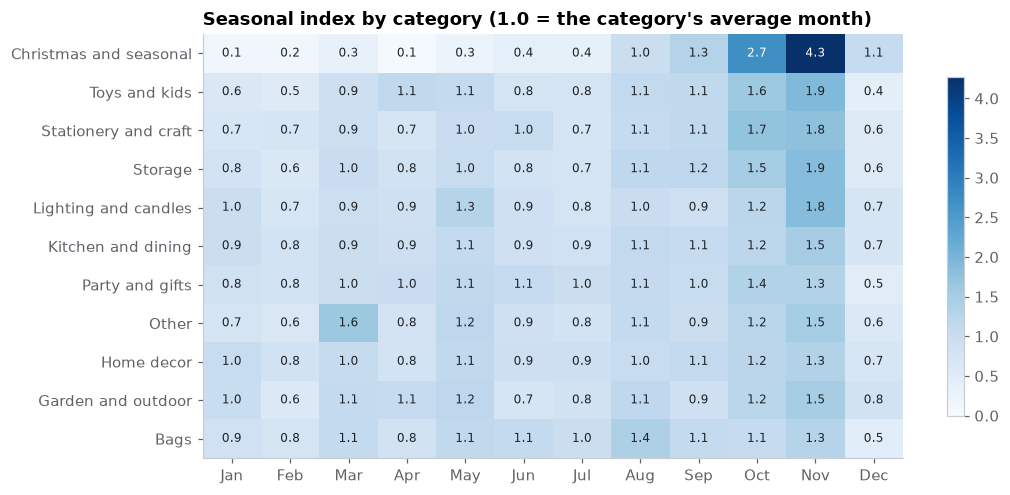

In [6]:
cat_week = demand.merge(products, on="product_id").assign(month=lambda d: d.week_start.dt.month)
idx = cat_week.groupby(["category", "month"]).units.sum().unstack()
idx = idx.div(idx.mean(axis=1), axis=0)
order = idx[[9, 10, 11]].mean(axis=1).sort_values(ascending=False).index
idx = idx.loc[order]
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(idx.values, cmap="Blues", aspect="auto", vmin=0, vmax=idx.values.max())
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(idx)), idx.index)
for i in range(idx.shape[0]):
    for j in range(idx.shape[1]):
        v = idx.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8, color="white" if v > idx.values.max() * 0.6 else INK)
ax.grid(False)
ax.set_title("Seasonal index by category (1.0 = the category's average month)")
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "demand_02_category_seasonality")

**Finding.** Seasonality is not one curve. Christmas items are almost dead until August and then spike several times above their average; garden and outdoor products peak in spring and summer; bags and kitchen items move much less. A single "last year's shape" applied to everything would be wrong for most categories, which is why the model below learns each product's own seasonal ratio.

### 4.2 Concentration: a few products carry the volume

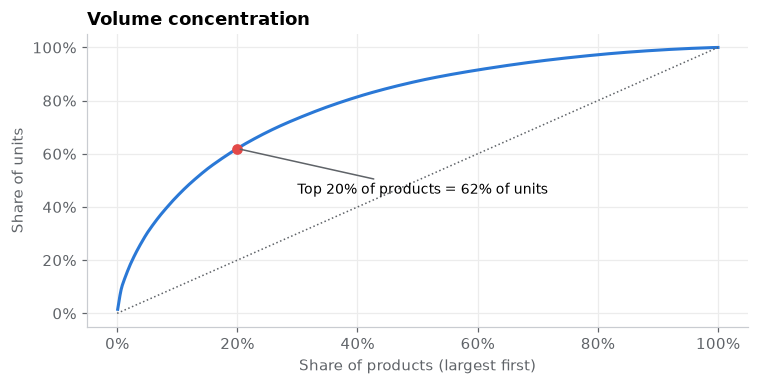

In [7]:
units_per_product = pd.Series(Y.sum(1), index=product_ids).sort_values(ascending=False)
cum = units_per_product.cumsum() / units_per_product.sum()
top20 = cum.iloc[int(len(cum) * 0.2) - 1]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, len(cum) + 1) / len(cum), cum.values, color=BLUE, lw=2)
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1)
ax.scatter([0.2], [top20], color=RED, zorder=3)
ax.annotate(f"Top 20% of products = {top20:.0%} of units", (0.2, top20), xytext=(0.3, 0.45),
            arrowprops={"arrowstyle": "-", "color": MUTED}, fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(xlabel="Share of products (largest first)", ylabel="Share of units", title="Volume concentration")
save(fig, "demand_03_concentration")

Because volume is concentrated, the error that matters is the error on the big sellers. WAPE weights every product by its volume, so it measures exactly that; a plain average of percentage errors would let a slow seller with 3 units count as much as a best seller with 30,000.

### 4.3 Intermittency: what kind of demand is this?

The Syntetos-Boylan classification places each product by how often it sells (ADI, the average interval between weeks with sales) and how variable the order sizes are (CV², the squared coefficient of variation of non-zero weeks). Wholesale demand is made of orders from a few hundred shops, so it is often *erratic*: something sells most weeks, but the quantity jumps.

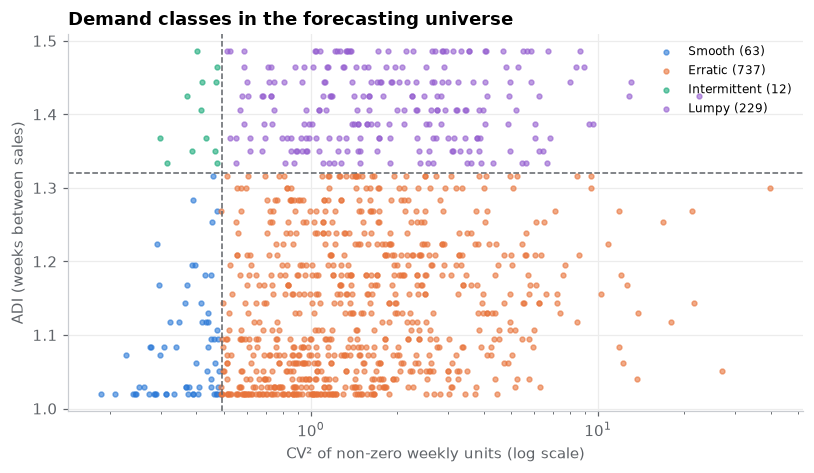

,products,share
demand_class,,
Erratic,737,71%
Lumpy,229,22%
Smooth,63,6%
Intermittent,12,1%


In [8]:
nz = np.where(Y > 0, Y, np.nan)
adi = Y.shape[1] / (Y > 0).sum(1)
cv2 = (np.nanstd(nz, axis=1) / np.nanmean(nz, axis=1)) ** 2
classes = pd.Series([dm.demand_class(pd.Series(row)) for row in Y], index=product_ids, name="demand_class")
colors = {"Smooth": BLUE, "Erratic": "#e8743b", "Intermittent": "#19a979", "Lumpy": "#945ecf"}
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for c, color in colors.items():
    m = (classes == c).values
    ax.scatter(cv2[m], adi[m], s=10, alpha=0.6, color=color, label=f"{c} ({m.sum()})")
ax.axvline(0.49, color=MUTED, ls="--", lw=1); ax.axhline(1.32, color=MUTED, ls="--", lw=1)
ax.set_xscale("log")
ax.set(xlabel="CV² of non-zero weekly units (log scale)", ylabel="ADI (weeks between sales)",
       title="Demand classes in the forecasting universe")
ax.legend(loc="upper right", fontsize=8)
save(fig, "demand_04_demand_classes")
classes.value_counts().to_frame("products").assign(share=lambda t: t.products / t.products.sum()).style.format({"share": "{:.0%}"})

**Finding.** Most products are *erratic*: they sell almost every week, but one large order can triple a week's volume. No method can predict the exact week a shop places a big order, so a large part of the weekly error is irreducible. Forecasting the four-week total (the purchasing quantity) instead of each week averages much of that noise out, and the error has to be read against this reality, not against textbook retail series.

## 5. Price architecture

Before looking at elasticity, it helps to understand how this business prices. Each product has three kinds of price in the data:

In [9]:
arch = con.sql("""
    with lines as (
        select product_id, cast(date_trunc('week', invoiced_at) as date) as week_start, channel, unit_price, quantity
        from stg_sales_lines where not is_cancellation and quantity > 0
    ),
    weekly as (
        select l.product_id, l.week_start, l.channel, l.unit_price, l.quantity, p.list_price
        from lines l
        join read_parquet('../data/processed/product_weekly_demand.parquet') p using (product_id, week_start)
        where p.list_price is not null
    )
    select
        median(unit_price / list_price) filter (where channel = 'Guest')                                  as guest_vs_list,
        median(unit_price / list_price) filter (where channel = 'Registered' and unit_price < list_price) as volume_tier_vs_list,
        sum(quantity) filter (where channel = 'Registered' and unit_price < list_price)
            / sum(quantity) filter (where channel = 'Registered')                                        as share_units_at_volume_price
    from weekly
""").df().iloc[0]
display(Markdown(f"""
| Price | What it is | Typical level |
|---|---|---|
| **List price** | Wholesale price for a standard order (highest price that covers at least 10% of a week's registered orders) | 1.00 |
| **Volume tier** | Lower price for bulk quantities | **{arch.volume_tier_vs_list:.2f}** x list, on {arch.share_units_at_volume_price:.0%} of registered units |
| **Guest price** | Orders without a customer account, typically small retail buyers | **{arch.guest_vs_list:.2f}** x list |
"""))


| Price | What it is | Typical level |
|---|---|---|
| **List price** | Wholesale price for a standard order (highest price that covers at least 10% of a week's registered orders) | 1.00 |
| **Volume tier** | Lower price for bulk quantities | **0.85** x list, on 41% of registered units |
| **Guest price** | Orders without a customer account, typically small retail buyers | **2.00** x list |


In [10]:
example = con.sql("""
    select channel, unit_price, count(*) as lines, sum(quantity) as units, median(quantity) as median_quantity
    from stg_sales_lines
    where product_id = '85099B' and not is_cancellation and quantity > 0
    group by 1, 2 having count(*) >= 20 order by lines desc
""").df()
display(Markdown("**Example: JUMBO BAG RED WHITE SPOTTY (85099B)**, price points with at least 20 order lines"))
example

**Example: JUMBO BAG RED WHITE SPOTTY (85099B)**, price points with at least 20 order lines

,channel,unit_price,lines,units,median_quantity
0,Registered,1.950,1762,"19,780.000",10.000
1,Registered,2.080,1075,"11,324.000",10.000
2,Guest,4.130,422,"1,685.000",2.000
3,Registered,1.650,303,"40,790.000",100.000
4,Guest,4.210,224,668.000,2.000
5,Registered,1.790,135,"19,136.000",100.000
6,Guest,1.950,37,228.000,5.000
7,Guest,4.300,24,58.000,1.500


This is classic **second-degree price discrimination** (volume tiers) plus **channel pricing** (guests pay about double). For a revenue manager these are the levers that matter here: the size of the volume discount and the order quantity that triggers it, and the guest premium. They are set by policy and almost never change, which matters for the next question.

## 6. Can this data measure price elasticity?

A demand model for pricing needs to know how units respond when the price changes. In this business the list price of a product changes rarely, so each change is a small **natural experiment**. The design:

1. For every product and month, take the list price (the most common weekly list price).
2. An **event** is a change of 0.5% to 35% that is preceded and followed by stable prices, so the change is a deliberate repricing and not noise between tiers.
3. Compare average log units in the 3 months after with the 3 months before (skipping the month of the change).
4. Subtract the same before-and-after change for **control products** whose price did not move in that window. This removes seasonality and anything that hit the whole catalogue (difference-in-differences).
5. The elasticity is the slope of the adjusted change in units on the change in log price, with a bootstrap confidence interval.

In [11]:
def price_change_events(df: pd.DataFrame, k: int = 3) -> pd.DataFrame:
    df = df.assign(month=df.week_start.dt.to_period("M"))
    units = df.pivot_table(index="product_id", columns="month", values="units", aggfunc="sum")
    price = (df.dropna(subset=["list_price"]).groupby(["product_id", "month"]).list_price
               .agg(lambda s: s.mode().iloc[0]).unstack().reindex(columns=units.columns))
    log_units, change = np.log1p(units), price.pct_change(axis=1, fill_method=None)
    rows = []
    for i in range(k, len(units.columns) - k):
        window = price.iloc[:, i - k:i + k + 1]
        stable = (window.nunique(axis=1) == 1) & window.notna().all(axis=1)
        diff = log_units.iloc[:, i + 1:i + 1 + k].mean(axis=1) - log_units.iloc[:, i - k:i].mean(axis=1)
        control = diff[stable].median()
        persists = (price.iloc[:, i + 1] == price.iloc[:, i]) & (price.iloc[:, i - 1] == price.iloc[:, i - k])
        c = change.iloc[:, i]
        events = c[(c.abs() > 0.005) & (c.abs() <= 0.35) & persists]
        rows += [{"product_id": p, "month": str(units.columns[i]), "price_change": v,
                  "dlog_price": np.log1p(v), "dlog_units_adjusted": diff[p] - control} for p, v in events.items()]
    return pd.DataFrame(rows).dropna()


def elasticity_with_ci(events: pd.DataFrame, n_boot: int = 2000, seed: int = 0) -> tuple[float, float, float]:
    slope = lambda e: (e.dlog_price * e.dlog_units_adjusted).sum() / (e.dlog_price ** 2).sum()
    rng = np.random.default_rng(seed)
    boots = [slope(events.iloc[rng.integers(0, len(events), len(events))]) for _ in range(n_boot)]
    return slope(events), *np.percentile(boots, [2.5, 97.5])


events = price_change_events(demand)
rows = []
for k in (2, 3, 4):
    e = price_change_events(demand, k)
    est, lo, hi = elasticity_with_ci(e)
    rows.append({"window (months before and after)": k, "events": len(e), "share of increases": (e.price_change > 0).mean(),
                 "elasticity": est, "95% CI low": lo, "95% CI high": hi})
event_table = pd.DataFrame(rows)
event_table.style.format({"share of increases": "{:.0%}", "elasticity": "{:.2f}", "95% CI low": "{:.2f}", "95% CI high": "{:.2f}"}).hide(axis="index")

window (months before and after),events,share of increases,elasticity,95% CI low,95% CI high
2,138,88%,-1.36,-2.27,-0.35
3,75,80%,-2.03,-3.01,-0.84
4,69,81%,-2.35,-3.61,-0.92


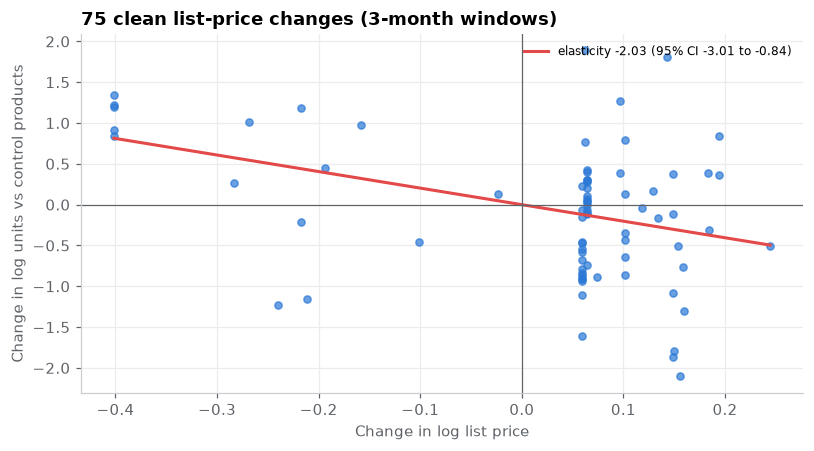

In [12]:
est, lo, hi = elasticity_with_ci(events)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.scatter(events.dlog_price, events.dlog_units_adjusted, s=22, color=BLUE, alpha=0.7)
x = np.linspace(events.dlog_price.min(), events.dlog_price.max(), 50)
ax.plot(x, est * x, color=RED, lw=2, label=f"elasticity {est:.2f} (95% CI {lo:.2f} to {hi:.2f})")
ax.axhline(0, color=MUTED, lw=0.8); ax.axvline(0, color=MUTED, lw=0.8)
ax.set(xlabel="Change in log list price", ylabel="Change in log units vs control products",
       title=f"{len(events)} clean list-price changes (3-month windows)")
ax.legend(loc="upper right", fontsize=8)
save(fig, "demand_05_price_change_events")

**What the natural experiment says.** Units do fall when list prices rise: the estimate is clearly negative, between about -1.4 and -2.3 depending on the window, so demand is **elastic** at the catalogue level. That is useful as an order of magnitude.

**Why it is not enough for pricing decisions.**
- **Few, one-sided experiments.** Only a hundred or so clean events exist in two years, most of them price *increases*. The confidence interval is roughly two units wide.
- **No product or category answer.** Splitting a hundred events across categories leaves a handful each.
- **No promotions.** There are no temporary price cuts, displays or advertising in this business, so promotional effects cannot be measured at all.
- **Timing is chosen by the business.** Repricing often happens before the peak season. The control products absorb the season, but not reasons specific to the repriced product.

Pricing and promotion analysis therefore continues in **notebook 03**, on a retail dataset built for it: weekly shelf prices, base prices, temporary price reductions, displays and circular features across 77 stores. This notebook focuses on what this data is excellent for: forecasting demand.

## 7. Validation design

A forecast is tested the way it will be used: standing at a date, using only the past, predicting the next four weeks.

- **Rolling origin.** Twelve forecast origins, every two weeks from June to November 2011. This half year covers a quiet summer and the full autumn ramp, the hardest period to get right.
- **Retrain at every origin.** The model is trained only on weeks whose four-week target had fully happened before the origin. Nothing from the future leaks in.
- **Target.** Units ordered in the four weeks starting at the origin, per product.

In [13]:
display(Markdown(
    f"{len(product_ids):,} products x 12 origins = {len(product_ids) * 12:,} forecasts per method. "
    f"The earliest training origin needs {dm.MIN_HISTORY} weeks of history (the longest recent-demand window); before week {dm.FULL_HISTORY} the last-year features are missing, which gradient boosting handles natively."))

1,041 products x 12 origins = 12,492 forecasts per method. The earliest training origin needs 26 weeks of history (the longest recent-demand window); before week 65 the last-year features are missing, which gradient boosting handles natively.

## 8. Baselines

Four methods a planner could run in a spreadsheet:

| Method | Forecast for the next four weeks |
|---|---|
| Last week x4 | Units last week, times four |
| Average of last 4 weeks | Recent average, times four |
| Average of last 13 weeks | Quarter average, times four: smooth but slow to react |
| Seasonal naive | The same four weeks last year, scaled by how much the product grew since |

A model is only worth running if it beats the best of these.

## 9. Global gradient boosting model

Instead of fitting a thousand small models, one **global** model learns from all products at once. Two design choices make that work:

1. **Everything is relative to the product's own level.** Each demand feature and the target are divided by the product's 13-week average. A best seller and a slow seller then look alike to the model ("last week was twice the usual level"), so patterns learned on one help the other. Training weights are the product's level, so big sellers count more, as in WAPE.
2. **Losses that match the question.** The point forecast uses a **Poisson** loss, natural for counts and robust to zeros. Two extra models use **quantile** losses for the 10th and 90th percentiles.

| Feature group | Features | What it captures |
|---|---|---|
| Recent demand | Lags 1 to 8, means of 4, 8 and 26 weeks | Momentum and level shifts |
| Regularity | Share of the last 13 weeks with sales, volatility, weeks since last sale | Erratic versus steady products, dormant products |
| Product seasonality | Same 4 weeks last year, the quarter before it, and their ratio | The product's own seasonal ramp |
| Catalogue seasonality | Last year's ratio and recent trend for all products together | The Christmas ramp, measured on stable totals |
| Calendar | Week of the year | Timing within the season |
| Size | Log of the product's level | Big sellers behave differently from small ones |

In [14]:
backtest = dm.backtest(Y, weeks, product_ids)
summary = dm.summarize(backtest)
summary.style.format({"wape_product": "{:.1%}", "bias": "{:+.1%}", "wape_total": "{:.1%}"})

,wape_product,bias,wape_total
method,,,
Last week x4,71.8%,-3.5%,16.3%
Average of last 4 weeks,52.7%,-6.1%,11.5%
Average of last 13 weeks,49.0%,-9.4%,12.8%
Seasonal naive,74.4%,+22.8%,22.8%
Global gradient boosting,47.5%,+3.6%,8.1%


## 10. Results

In [15]:
s = summary
best = s.loc[dm.BASELINES, "wape_product"].idxmin()
gb = s.loc[dm.MODEL]
display(Markdown(f"""
- **Product level:** WAPE **{gb.wape_product:.1%}** against **{s.loc[best, 'wape_product']:.1%}** for the best baseline ({best.lower()}), a **{1 - gb.wape_product / s.loc[best, 'wape_product']:.0%}** relative reduction.
- **Bias:** **{gb.bias:+.1%}** against {s.loc[best, 'bias']:+.1%} for the same baseline. The baselines under-forecast the autumn ramp; the model keeps total stock close to real demand.
- **Catalogue total:** WAPE **{gb.wape_total:.1%}** against {s.loc[dm.BASELINES, 'wape_total'].min():.1%} for the best baseline on totals.
- **Seasonal naive** is the worst method: the catalogue changes from one year to the next, so last year's exact numbers are a poor guide even after scaling.
"""))


- **Product level:** WAPE **47.5%** against **49.0%** for the best baseline (average of last 13 weeks), a **3%** relative reduction.
- **Bias:** **+3.6%** against -9.4% for the same baseline. The baselines under-forecast the autumn ramp; the model keeps total stock close to real demand.
- **Catalogue total:** WAPE **8.1%** against 11.5% for the best baseline on totals.
- **Seasonal naive** is the worst method: the catalogue changes from one year to the next, so last year's exact numbers are a poor guide even after scaling.


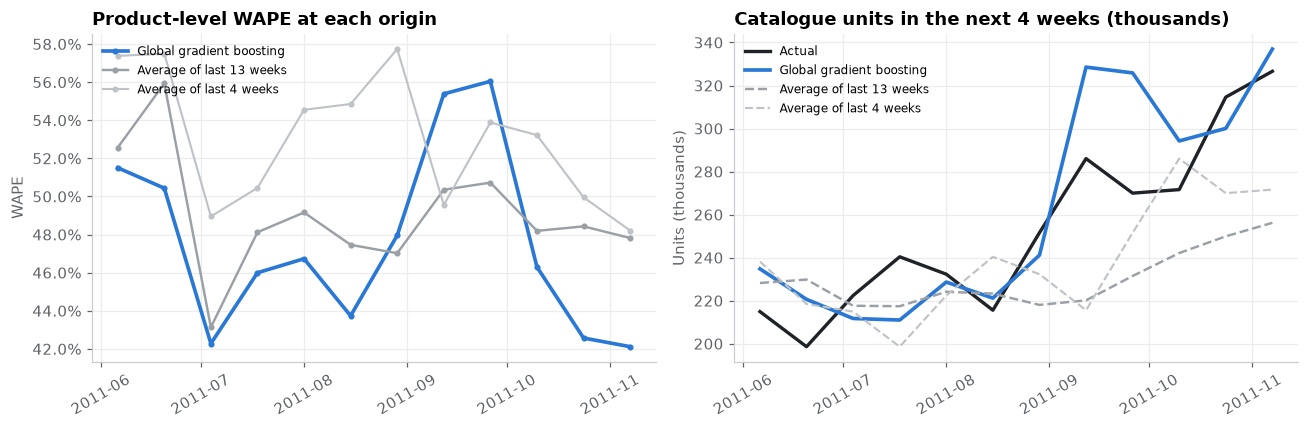

In [16]:
per_origin = (backtest.groupby(["method", "origin"])[["actual", "forecast"]]
              .apply(lambda d: dm.wape(d.actual, d.forecast)).unstack(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
styles = {dm.MODEL: (BLUE, 2.4), "Average of last 13 weeks": (GRAY, 1.6), "Average of last 4 weeks": ("#bfc3c8", 1.4)}
for m, (color, lw) in styles.items():
    axes[0].plot(per_origin.index, per_origin[m], color=color, lw=lw, marker="o", ms=3, label=m)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set(title="Product-level WAPE at each origin", ylabel="WAPE")
axes[0].legend(fontsize=8, loc="upper left")
totals = backtest.groupby(["method", "origin"])[["actual", "forecast"]].sum()
act = totals.loc[dm.MODEL, "actual"]
axes[1].plot(act.index, act / 1e3, color=INK, lw=2.2, label="Actual")
for m, (color, lw) in styles.items():
    axes[1].plot(act.index, totals.loc[m, "forecast"] / 1e3, color=color, lw=lw, ls="--" if m != dm.MODEL else "-", label=m)
axes[1].set(title="Catalogue units in the next 4 weeks (thousands)", ylabel="Units (thousands)")
axes[1].legend(fontsize=8, loc="upper left")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
save(fig, "demand_06_backtest_by_origin")

The right panel shows where the model earns its keep. Moving averages always lag a ramp: in September and October they forecast last month's level while orders keep climbing, and the shortfall is exactly the stock that would be missing at the peak. The model reads the seasonal ratio from last year and the current catalogue trend, so it anticipates the ramp: in September and October it overshoots by roughly 10 to 15%, then tracks November closely. For a peak season that is the cheaper mistake; running out of Christmas stock in November costs sales that cannot be recovered.

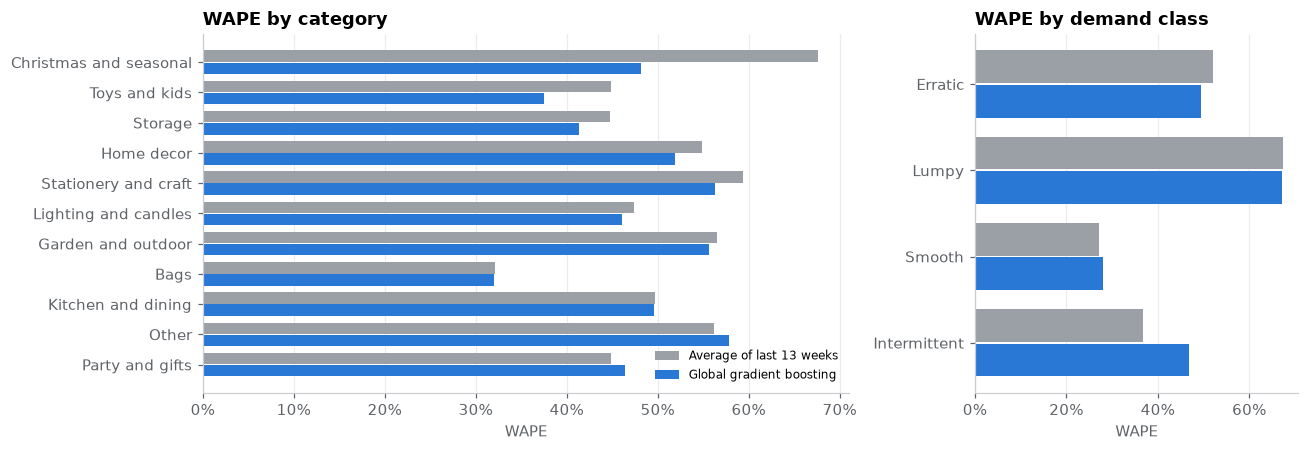

method,Average of last 13 weeks,Global gradient boosting,improvement
category,,,
Christmas and seasonal,67.7%,48.2%,28.7%
Toys and kids,44.9%,37.5%,16.5%
Storage,44.8%,41.3%,7.7%
Home decor,54.9%,51.9%,5.5%
Stationery and craft,59.4%,56.3%,5.3%
Lighting and candles,47.4%,46.1%,2.6%
Garden and outdoor,56.5%,55.7%,1.6%
Bags,32.2%,32.0%,0.5%
Kitchen and dining,49.7%,49.6%,0.2%


In [17]:
cat_map = products.set_index("product_id").category
backtest["category"] = backtest.product_id.map(cat_map)
backtest["demand_class"] = backtest.product_id.map(classes)

def compare(group_col):
    t = (backtest[backtest.method.isin([dm.MODEL, best])]
         .groupby([group_col, "method"])[["actual", "forecast"]]
         .apply(lambda d: dm.wape(d.actual, d.forecast)).unstack())
    t["improvement"] = 1 - t[dm.MODEL] / t[best]
    return t.sort_values("improvement", ascending=False)

by_cat = compare("category")
by_class = compare("demand_class")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2, 1]})
for ax, t, title in [(axes[0], by_cat, "By category"), (axes[1], by_class, "By demand class")]:
    y = np.arange(len(t))
    ax.barh(y - 0.2, t[best], height=0.38, color=GRAY, label=best)
    ax.barh(y + 0.2, t[dm.MODEL], height=0.38, color=BLUE, label=dm.MODEL)
    ax.set_yticks(y, t.index); ax.invert_yaxis()
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
    ax.set(title=f"WAPE {title.lower()}", xlabel="WAPE")
    ax.grid(axis="y", visible=False)
axes[0].legend(fontsize=8, loc="lower right")
save(fig, "demand_07_wape_by_segment")
by_cat.style.format("{:.1%}")

The gain is largest for Christmas and seasonal products, where moving averages miss the ramp entirely; that is what the seasonal features are for. In steady categories (bags, kitchen) the two are level, and in party and gifts the moving average is slightly better: where there is no seasonal ramp to anticipate, a smooth average is hard to beat. For lumpy products everything struggles and for the few intermittent ones the moving average wins, a reminder that the remaining error is mostly order-size noise that no forecast removes; safety stock handles it, sized by the intervals in the next section.

## 11. Prediction intervals

Purchasing needs a range, not just a number: buy for the median, hold safety stock for the upside. The quantile models give a 10th and a 90th percentile, so 80% of outcomes should fall between them.

Quantile models trained on past data are often over-confident on new data. **Conformalized quantile regression** fixes that with a simple, distribution-free step: measure how far past outcomes fell outside their intervals (in units of each product's level) and widen future intervals by the amount that would have covered 80% of them. In the backtest this is done sequentially: each origin is calibrated only with origins whose outcomes were already known.

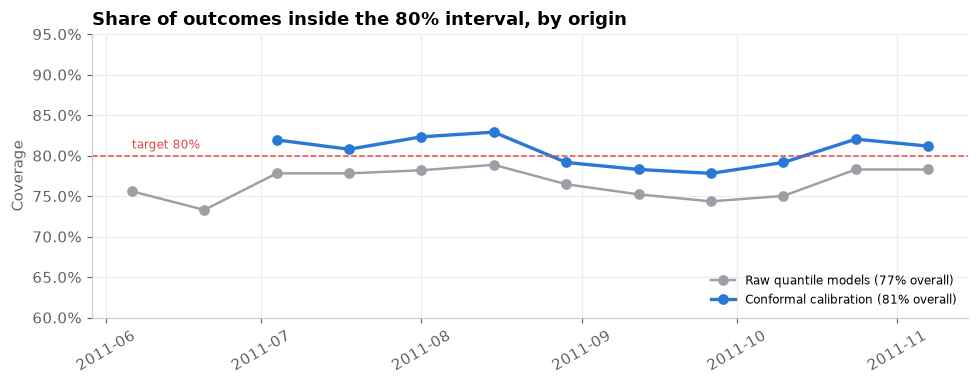

In [18]:
g = backtest[backtest.method == dm.MODEL]
raw = ((g.actual >= g.p10) & (g.actual <= g.p90)).mean()
c = g.dropna(subset=["p10_cal"])
cal = ((c.actual >= c.p10_cal) & (c.actual <= c.p90_cal)).mean()
cov = pd.DataFrame({
    "Raw quantile models": g.groupby("origin").apply(lambda d: ((d.actual >= d.p10) & (d.actual <= d.p90)).mean()),
    "Conformal calibration": c.groupby("origin").apply(lambda d: ((d.actual >= d.p10_cal) & (d.actual <= d.p90_cal)).mean()),
})
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(cov.index, cov["Raw quantile models"], color=GRAY, marker="o", lw=1.6, label=f"Raw quantile models ({raw:.0%} overall)")
ax.plot(cov.index, cov["Conformal calibration"], color=BLUE, marker="o", lw=2.2, label=f"Conformal calibration ({cal:.0%} overall)")
ax.axhline(0.8, color=RED, ls="--", lw=1); ax.text(cov.index[0], 0.805, "target 80%", color=RED, fontsize=8, va="bottom")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0.6, 0.95)
ax.set(title="Share of outcomes inside the 80% interval, by origin", ylabel="Coverage")
ax.legend(fontsize=8, loc="lower right")
ax.tick_params(axis="x", rotation=30)
save(fig, "demand_08_interval_coverage")

The raw intervals cover too little; after calibration coverage sits at the 80% target. That turns the interval into something purchasing can use directly: ordering up to the 90th percentile means running out in about one cycle in ten.

## 12. What drives the forecast

Permutation importance is a common way to rank features, but it misleads here: shuffling one feature across products creates impossible combinations (a best seller that "never sells"), and features shared by all products at an origin, like the week of the year, cannot be shuffled at all. A cleaner test is an **ablation**: rerun the whole backtest without a group of features and see what gets worse. Each run retrains the model at all twelve origins, so this cell takes a few minutes.

In [19]:
def run_variant(drop=()):
    with dm.excluding(*drop):
        bt = dm.backtest(Y, weeks, product_ids)
        s = dm.summarize(bt).loc[dm.MODEL]
        final = dm.predict(dm.fit_models(Y, weeks, len(weeks)), Y, weeks, len(weeks))
    return {"product WAPE": s.wape_product, "bias": s.bias, "catalogue WAPE": s.wape_total,
            "December forecast (units)": final.p50.sum()}

variants = {"Full model": run_variant()}
for group in ["Product seasonality (last year)", "Catalogue seasonality and calendar"]:
    variants[f"Without {group.lower()}"] = run_variant(dm.FEATURE_GROUPS[group])
ablation = pd.DataFrame(variants).T
ablation.style.format({"product WAPE": "{:.1%}", "bias": "{:+.1%}", "catalogue WAPE": "{:.1%}",
                       "December forecast (units)": "{:,.0f}"})

,product WAPE,bias,catalogue WAPE,December forecast (units)
Full model,47.5%,+3.6%,8.1%,"150,488"
Without product seasonality (last year),48.4%,+2.9%,8.2%,"146,237"
Without catalogue seasonality and calendar,45.1%,-6.6%,8.4%,"267,990"


**Reading the ablation.**

- **Catalogue seasonality and calendar** (the catalogue-wide seasonal ratio and trend, and the week of the year) are what keep the *total* right. Without them the product-level WAPE actually improves a little, but the forecast turns into a systematic under-forecast during the autumn ramp and the catalogue error rises, and the December forecast jumps far above what the first days of December suggest (see section 13). Product WAPE alone would have picked the wrong model; that is why the three metrics are read together.
- **Product seasonality** (each product's own last-year pattern) adds less than expected: removing it costs about one point of product WAPE. A single product's last year is noisy, and the catalogue-wide seasonal signal carries most of the timing information.
- Recent demand and regularity features set the level and are not optional: without them there is nothing to forecast from.

The full model is kept: it is the best compromise between product accuracy, bias and the catalogue total, which is what purchasing, the warehouse and finance each care about.

## 13. The December 2011 forecast

The production run (`python -m retail_intelligence.demand`) retrains on all 104 weeks and forecasts the four weeks from 5 December 2011, with intervals widened by the conformal margin learned in the backtest.

In [20]:
forecast = pd.read_csv(DATA_PROCESSED / "demand_forecast.csv", dtype={"product_id": str})
metrics = json.loads((ROOT / "reports" / "demand_metrics.json").read_text())
display(Markdown(
    f"Window **{metrics['forecast_window'][0]} to {metrics['forecast_window'][1]}**: "
    f"{forecast.p50.sum():,.0f} units expected across {len(forecast):,} products "
    f"(80% range for the total of each product summed: {forecast.p10.sum():,.0f} to {forecast.p90.sum():,.0f}). "
    f"The same four weeks of 2010 had {Y[:, len(weeks) - 52:len(weeks) - 48].sum():,.0f} units."))
forecast.sort_values("p50", ascending=False).head(10)[["product_id", "description", "category", "last_4_weeks", "p10", "p50", "p90"]]

Window **2011-12-05 to 2012-01-01**: 150,488 units expected across 1,041 products (80% range for the total of each product summed: 49,544 to 285,221). The same four weeks of 2010 had 178,418 units.

,product_id,description,category,last_4_weeks,p10,p50,p90
534,22197,SMALL POPCORN HOLDER,Kitchen and dining,"13,268.000","1,826.800","4,033.100","4,334.500"
468,22086,PAPER CHAIN KIT 50'S CHRISTMAS,Christmas and seasonal,"6,842.000","1,004.400","2,356.800","3,342.200"
1011,85099B,JUMBO BAG RED RETROSPOT,Bags,"5,604.000","1,506.200","2,171.100","3,133.600"
962,84879,ASSORTED COLOUR BIRD ORNAMENT,Garden and outdoor,"5,029.000","1,221.900","1,891.900","2,773.000"
923,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,Toys and kids,"3,941.000",735.000,"1,508.100","2,526.300"
32,20668,DISCO BALL CHRISTMAS DECORATION,Christmas and seasonal,"4,746.000",566.000,"1,381.300","2,461.500"
1016,85123A,WHITE HANGING HEART T-LIGHT HOLDER,Lighting and candles,"3,519.000",780.400,"1,211.000","1,965.400"
927,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,Lighting and candles,"3,227.000",541.100,"1,161.500","2,052.300"
714,22492,MINI PAINT SET VINTAGE,Toys and kids,"3,106.000",581.500,"1,060.300","1,862.000"
167,21212,PACK OF 72 RETROSPOT CAKE CASES,Kitchen and dining,"1,837.000",622.300,943.900,"1,730.300"


### A first reality check

The extract ends on Friday 9 December 2011, so the first five trading days of the forecast window are already in the raw data, even though they were never used for training (the week is incomplete). Comparing them with the same days of 2010 gives a rough read on the December forecast.

In [21]:
check = con.sql("""
    with u as (select distinct product_id from read_parquet('../data/processed/product_weekly_demand.parquet'))
    select cast(date_trunc('week', invoiced_at) as date) as week_start,
           count(distinct invoiced_at::date) as trading_days, sum(quantity) as units
    from stg_sales_lines join u using (product_id)
    where not is_cancellation and quantity > 0
      and (invoiced_at >= '2010-12-06' and invoiced_at < '2011-01-03' or invoiced_at >= '2011-12-05')
    group by 1 order by 1
""").df()
ly_total, ly_first = check.units.iloc[:-1].sum(), check.units.iloc[0]
this_first = check.units.iloc[-1]
implied = ly_total * (this_first / check.trading_days.iloc[-1]) / (ly_first / check.trading_days.iloc[0])
display(check)
display(Markdown(
    f"First week of December 2011: **{this_first:,.0f} units in {check.trading_days.iloc[-1]} trading days**, "
    f"against {ly_first:,.0f} in {check.trading_days.iloc[0]} days a year earlier. If the rest of the month follows "
    f"2010's pattern, the four-week total would be about **{implied:,.0f} units**; the model forecasts "
    f"**{forecast.p50.sum():,.0f}** ({forecast.p50.sum() / implied - 1:+.0%})."))

,week_start,trading_days,units
0,2010-12-06,6,"84,037.000"
1,2010-12-13,6,"66,819.000"
2,2010-12-20,4,"27,562.000"
3,2011-12-05,5,"78,119.000"


First week of December 2011: **78,119 units in 5 trading days**, against 84,037 in 6 days a year earlier. If the rest of the month follows 2010's pattern, the four-week total would be about **199,024 units**; the model forecasts **150,488** (-24%).

The early signal says the December forecast is **too low by about a quarter**, although the implied total still sits inside the summed 80% range. The reason is structural: to learn the pre-Christmas slowdown the model has exactly one past December (2010), when the drop was much steeper than in 2011. This is the kind of check a planner would run in the first days of the month, and it is the first improvement listed in section 15.

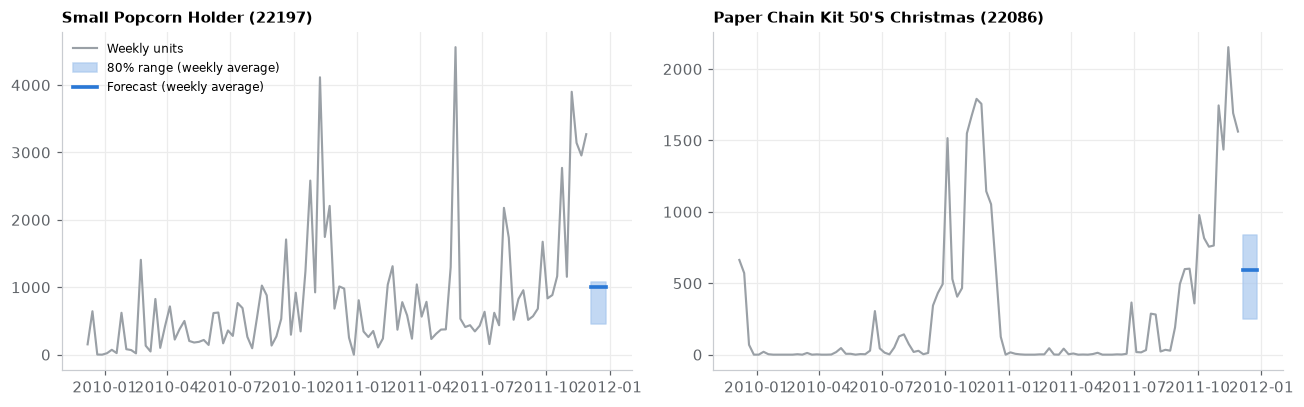

In [22]:
def plot_product(pid, ax):
    h = demand[demand.product_id == pid].set_index("week_start").units
    f = forecast[forecast.product_id == pid].iloc[0]
    ax.plot(h.index, h.values, color=GRAY, lw=1.4, label="Weekly units")
    start = pd.Timestamp(f.forecast_start)
    span = pd.date_range(start, periods=4, freq="7D")
    ax.fill_between(span, f.p10 / 4, f.p90 / 4, color=LIGHT_BLUE, alpha=0.7, label="80% range (weekly average)")
    ax.plot(span, [f.p50 / 4] * 4, color=BLUE, lw=2.4, label="Forecast (weekly average)")
    ax.set_title(f"{f.description.title()} ({pid})", fontsize=10)

top = forecast.sort_values("p50", ascending=False).product_id.tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for pid, ax in zip([top[0], forecast[forecast.category == "Christmas and seasonal"].sort_values("p50").product_id.iloc[-1]], axes):
    plot_product(pid, ax)
axes[0].legend(fontsize=8, loc="upper left")
save(fig, "demand_10_example_forecasts")

## 14. Conclusions

1. **Demand needed its own data model.** Guest orders, closed weeks and partial weeks are irrelevant to customer retention but distort a forecast. The dbt project now has an all-channel staging layer, a complete product-week grid and a tested category mapping.
2. **This demand is erratic by nature.** Wholesale orders come in lumps, so even a good forecast has a large error at product level. Forecasting the four-week purchasing quantity, not each week, is the right grain.
3. **The global model beats every baseline** on product WAPE and especially on the catalogue total, where it cuts the error of the best moving average by about 30%, with a much smaller bias. The gain comes from reading the seasonal ramp instead of lagging it, and it is largest for Christmas products.
4. **The intervals are honest after calibration.** Conformal calibration turns over-confident quantile models into an 80% range that covers about 80% of outcomes, which is what safety stock needs.
5. **Elasticity is negative but imprecise here.** A difference-in-differences on list-price changes finds elastic demand (around -1.4 to -2.3) with wide intervals and no promotions to study. Product-level pricing needs richer price variation, which is what notebook 03 provides.

## 15. Limitations and next steps

| Area | Limitation | Next step |
|---|---|---|
| December | Only one past December (2010) exists to learn the pre-Christmas slowdown, and the reality check suggests the December 2011 forecast is low | Add more years of history, or a holiday calendar feature (weeks to Christmas, closure weeks), and track the first week of each month as an early signal |
| Hierarchy | Product forecasts are made independently | Reconcile product, category and total forecasts (MinT reconciliation) so plans add up |
| New products | Products with fewer than 70 selling weeks are excluded | Cold-start forecasts from similar products (same category, price band, launch season) |
| Cancellations | Demand is gross orders; about 2% are cancelled later | Net cancellations back to the original order week |
| Big orders | A few customers drive most of the variance of some products | Model order count and order size separately, or treat known large accounts explicitly |
| From forecast to stock | The output is a forecast, not an order quantity | Turn P50 and P90 into order-up-to levels with supplier lead times and a target service level |
| Model | One gradient boosting configuration | Tune with time-series cross-validation; try LightGBM with Tweedie loss and direct multi-horizon targets |

In [23]:
con.close()